In [ ]:
# Cell 1: Environment Setup & File Upload
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score, classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

# Visual formatting
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Google Colab file upload widget
from google.colab import files
print("Please upload your dataset file (Excel .xlsx or CSV .csv):")
uploaded = files.upload()

# Automatically load the uploaded file
file_name = list(uploaded.keys())[0]
if file_name.endswith('.xlsx') or file_name.endswith('.xls'):
    df = pd.read_excel(file_name)
else:
    df = pd.read_csv(file_name)

print(f"\n✅ Successfully loaded '{file_name}' with {df.shape[0]} rows and {df.shape[1]} columns.")
df.head()

Please upload your dataset file (Excel .xlsx or CSV .csv):


Saving Sample data (1).xlsx to Sample data (1).xlsx

✅ Successfully loaded 'Sample data (1).xlsx' with 700 rows and 16 columns.


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.00,3,350,529550.00,0.00,529550.00,393380.00,136170.00,2014-12-01,12,December,2014
1,Government,Germany,Paseo,NaN,1006.00,10,350,352100.00,0.00,352100.00,261560.00,90540.00,2014-06-01,6,June,2014
2,Government,Canada,Paseo,NaN,1725.00,10,350,603750.00,0.00,603750.00,448500.00,155250.00,2013-11-01,11,November,2013
3,Government,Germany,Paseo,NaN,1513.00,10,350,529550.00,0.00,529550.00,393380.00,136170.00,2014-12-01,12,December,2014
4,Government,Germany,Velo,NaN,1006.00,120,350,352100.00,0.00,352100.00,261560.00,90540.00,2014-06-01,6,June,2014


In [ ]:
# Cell 2: Data Cleaning & Preparation
# 1. Clean hidden whitespace in column headers
df.columns = df.columns.str.strip()

# 2. Parse Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# 3. Impute missing Discount Band with 'None' (representing 0% discount)
df['Discount Band'] = df['Discount Band'].fillna('None')

# 4. Feature Engineering: Profit Margin % and Binary Loss Indicator
df['Profit_Margin_Pct'] = (df['Profit'] / df['Sales']) * 100
df['Is_Profitable'] = (df['Profit'] > 0).astype(int)

print("--- Data Hygiene Audit ---")
print(f"• Duplicate Rows: {df.duplicated().sum()}")
print(f"• Missing Values: {df.isnull().sum().sum()}")
df.info()

--- Data Hygiene Audit ---
• Duplicate Rows: 0
• Missing Values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    object        
 1   Country              700 non-null    object        
 2   Product              700 non-null    object        
 3   Discount Band        700 non-null    object        
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9   Sales                700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 

In [ ]:
# Cell 3: Executive Financial KPIs
total_gross = df['Gross Sales'].sum()
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_cogs = df['COGS'].sum()
total_discounts = df['Discounts'].sum()
total_units = df['Units Sold'].sum()
overall_margin = (total_profit / total_sales) * 100

print("=" * 55)
print("             EXECUTIVE FINANCIAL SUMMARY             ")
print("=" * 55)
print(f"Total Gross Sales:       ${total_gross:,.2f}")
print(f"Total Discounts Given:   ${total_discounts:,.2f}")
print(f"Total Net Sales Revenue: ${total_sales:,.2f}")
print(f"Cost of Goods Sold:      ${total_cogs:,.2f}")
print(f"Total Net Profit:        ${total_profit:,.2f}")
print(f"Overall Profit Margin:   {overall_margin:.2f}%")
print(f"Total Units Sold:        {total_units:,.0f} units")
print("=" * 55)

             EXECUTIVE FINANCIAL SUMMARY             
Total Gross Sales:       $127,931,598.50
Total Discounts Given:   $9,205,248.24
Total Net Sales Revenue: $118,726,350.26
Cost of Goods Sold:      $101,832,648.00
Total Net Profit:        $16,893,702.26
Overall Profit Margin:   14.23%
Total Units Sold:        1,125,806 units


--- Performance by Country ---


,Sales,Profit,Units_Sold,Margin_Pct
Country,,,,
United States of America,25029830.16,2995540.67,232627.50,11.97
Canada,24887654.89,3529228.89,247428.50,14.18
France,24354172.28,3781020.78,240931.00,15.53
Germany,23505340.82,3680388.82,201494.00,15.66
Mexico,20949352.11,2907523.11,203325.00,13.88



--- Performance by Customer Segment ---


,Sales,Profit,Units_Sold,Margin_Pct
Segment,,,,
Government,52504260.67,11388173.17,470673.50,21.69
Small Business,42427918.50,4143168.50,153139.00,9.77
Enterprise,19611694.38,-614545.62,168552.00,-3.13
Midmarket,2381883.08,660103.07,172178.00,27.71
Channel Partners,1800593.64,1316803.14,161263.50,73.13



⚠️ Loss-making deals: 58 deals | Total Losses: $-777,321.25
Losses distribution by Segment:
Segment
Enterprise    58
Name: count, dtype: int64


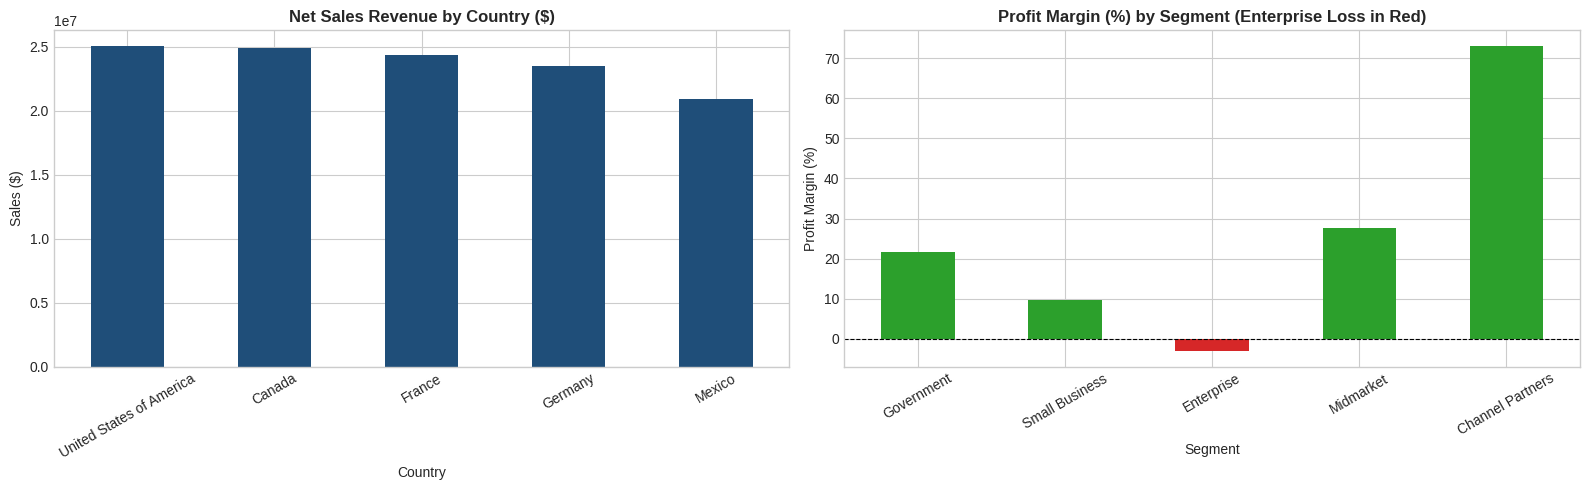

In [ ]:
# Cell 4: Deep-Dive Analysis & Visualizations

# 4.1 Country Performance
country_summary = df.groupby('Country').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units Sold', 'sum')
).sort_values(by='Sales', ascending=False)
country_summary['Margin_Pct'] = (country_summary['Profit'] / country_summary['Sales']) * 100
print("--- Performance by Country ---")
display(country_summary)

# 4.2 Customer Segment Breakdown & The Enterprise Loss
segment_summary = df.groupby('Segment').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units Sold', 'sum')
).sort_values(by='Sales', ascending=False)
segment_summary['Margin_Pct'] = (segment_summary['Profit'] / segment_summary['Sales']) * 100
print("\n--- Performance by Customer Segment ---")
display(segment_summary)

losses = df[df['Profit'] < 0]
print(f"\n⚠️ Loss-making deals: {len(losses)} deals | Total Losses: ${losses['Profit'].sum():,.2f}")
print("Losses distribution by Segment:")
print(losses['Segment'].value_counts())

# 4.3 Side-by-Side Visual Charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Country Sales Chart
country_summary['Sales'].plot(kind='bar', ax=ax1, color='#1f4e79')
ax1.set_title('Net Sales Revenue by Country ($)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Sales ($)')
ax1.tick_params(axis='x', rotation=30)

# Segment Profit Margin Chart (Enterprise Highlighted in Red)
colors = ['#2ca02c' if m > 0 else '#d62728' for m in segment_summary['Margin_Pct']]
segment_summary['Margin_Pct'].plot(kind='bar', ax=ax2, color=colors)
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.set_title('Profit Margin (%) by Segment (Enterprise Loss in Red)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Profit Margin (%)')
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

=== REGRESSION MODEL BENCHMARKS ===
• Linear Regression:  R² = 0.7624 | MAE = $82,988.26
• Random Forest:      R² = 0.9858 | MAE = $10,432.53


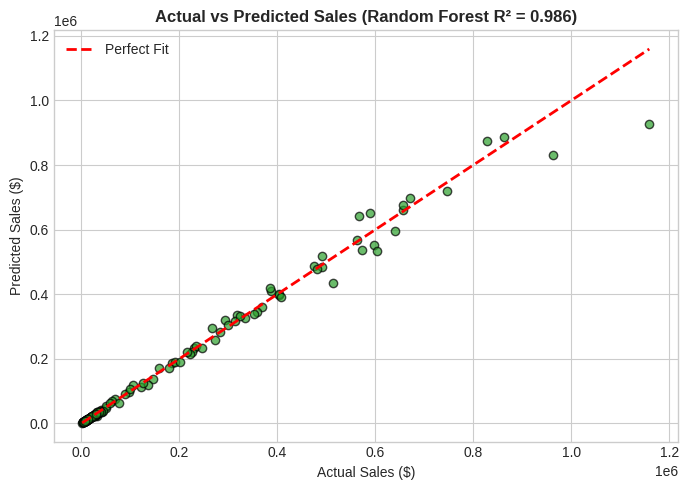

In [ ]:
# Cell 5: Sales Revenue Forecasting
features = ['Units Sold', 'Sale Price', 'Manufacturing Price', 'Country', 'Product', 'Segment', 'Discount Band']
X = df[features]
y = df['Sales']

cat_cols = ['Country', 'Product', 'Segment', 'Discount Band']
preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model 1: Linear Regression
lr_pipe = make_pipeline(preprocessor, LinearRegression())
lr_pipe.fit(X_train, y_train)
lr_preds = lr_pipe.predict(X_test)

# Model 2: Random Forest Regressor
rf_pipe = make_pipeline(preprocessor, RandomForestRegressor(n_estimators=100, random_state=42))
rf_pipe.fit(X_train, y_train)
rf_preds = rf_pipe.predict(X_test)

print("=== REGRESSION MODEL BENCHMARKS ===")
print(f"• Linear Regression:  R² = {r2_score(y_test, lr_preds):.4f} | MAE = ${mean_absolute_error(y_test, lr_preds):,.2f}")
print(f"• Random Forest:      R² = {r2_score(y_test, rf_preds):.4f} | MAE = ${mean_absolute_error(y_test, rf_preds):,.2f}")

# Plot Actual vs. Predicted (Random Forest)
plt.figure(figsize=(7, 5))
plt.scatter(y_test, rf_preds, alpha=0.7, color='#2ca02c', edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Fit')
plt.title(f"Actual vs Predicted Sales (Random Forest R² = {r2_score(y_test, rf_preds):.3f})", fontsize=12, fontweight='bold')
plt.xlabel("Actual Sales ($)")
plt.ylabel("Predicted Sales ($)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Cell 6: Deal Profitability Classification Model
y_clf = df['Is_Profitable']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

clf_pipe = make_pipeline(preprocessor, RandomForestClassifier(n_estimators=100, random_state=42))
clf_pipe.fit(X_train_c, y_train_c)
clf_preds = clf_pipe.predict(X_test_c)

print("=== TEST SET CLASSIFICATION RESULTS ===")
print(f"Overall Test Accuracy: {accuracy_score(y_test_c, clf_preds)*100:.2f}%\n")

cm = confusion_matrix(y_test_c, clf_preds)
cm_df = pd.DataFrame(cm, index=['Actual Loss (0)', 'Actual Profit (1)'], columns=['Pred Loss (0)', 'Pred Profit (1)'])
print("Confusion Matrix (n = 140 Test Deals):")
display(cm_df)

print("\nDetailed Classification Report:")
print(classification_report(y_test_c, clf_preds, target_names=['Loss Deal (0)', 'Profitable Deal (1)']))

=== TEST SET CLASSIFICATION RESULTS ===
Overall Test Accuracy: 99.29%

Confusion Matrix (n = 140 Test Deals):


,Pred Loss (0),Pred Profit (1)
Actual Loss (0),12,1
Actual Profit (1),0,127



Detailed Classification Report:
                     precision    recall  f1-score   support

      Loss Deal (0)       1.00      0.92      0.96        13
Profitable Deal (1)       0.99      1.00      1.00       127

           accuracy                           0.99       140
          macro avg       1.00      0.96      0.98       140
       weighted avg       0.99      0.99      0.99       140



Top 10 Most Important Features Driving Deal Profitability:


,0
Segment_Enterprise,0.34
Sale Price,0.16
Discount Band_Low,0.11
Units Sold,0.08
Segment_Government,0.05
Discount Band_Medium,0.05
Discount Band_High,0.04
Segment_Small Business,0.03
Discount Band_None,0.03
Manufacturing Price,0.02


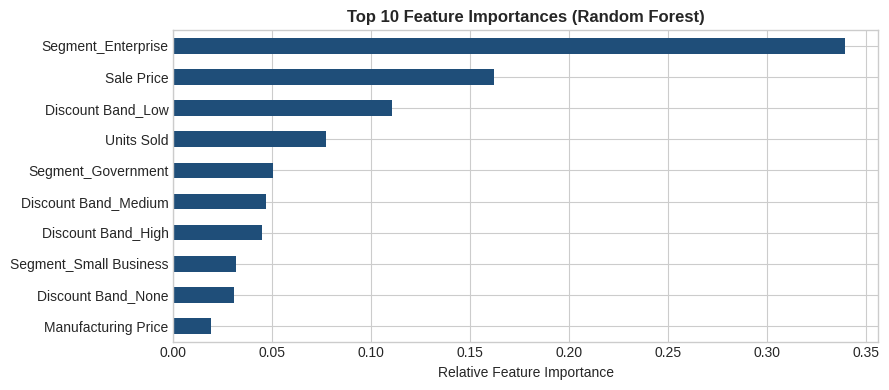

In [ ]:
# Cell 7: Feature Importance Extraction
cat_features = clf_pipe.named_steps['columntransformer'].named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
num_features = ['Units Sold', 'Sale Price', 'Manufacturing Price']
all_features = cat_features + num_features

rf_classifier = clf_pipe.named_steps['randomforestclassifier']
feat_importance = pd.Series(rf_classifier.feature_importances_, index=all_features).sort_values(ascending=False)

print("Top 10 Most Important Features Driving Deal Profitability:")
display(feat_importance.head(10))

# Horizontal Bar Chart
plt.figure(figsize=(9, 4))
feat_importance.head(10).plot(kind='barh', color='#1f4e79').invert_yaxis()
plt.title('Top 10 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Relative Feature Importance')
plt.tight_layout()
plt.show()